# ACME Talent Insights

**Answers to the seven performance and talent questions, computed from the pipeline's Gold layer.**

| | |
|---|---|
| **Audience** | HR leaders and managers. No coding is needed to read it: every section starts with the answer in plain language. |
| **Source** | The `talent-etl` pipeline's **Gold layer**: cleaned, validated tables built from PostgreSQL and the learning-event files. |
| **Freshness** | Every number and chart is computed live from Gold. Rerun the pipeline, then this notebook, and everything updates. |

**How each section is laid out:** the question → **the answer** → how it was worked out → charts → a small table with exact values → **caveats** (what the data cannot tell us).

**Contents**
1. [Executive summary](#Executive-summary)
2. [Where the data comes from](#Where-the-data-comes-from)
3. [Q1 Performance ratings and review history](#Q1.-Performance-ratings-and-review-history-for-each-employee)
4. [Q2 Critical skill gaps](#Q2.-Which-employees-have-critical-skill-gaps-in-key-competencies?)
5. [Q3 High-potential employees ready for promotion](#Q3.-Who-are-the-high-potential-employees-ready-for-promotion?)
6. [Q4 Training and development completed](#Q4.-What-training-and-development-has-each-employee-completed?)
7. [Q5 Attrition risk from performance trends](#Q5.-Which-employees-are-at-risk-of-attrition-based-on-performance-trends?)
8. [Q6 Performance vs team and project outcomes](#Q6.-How-does-employee-performance-correlate-with-team-and-project-outcomes?)
9. [Q7 Distribution of skills](#Q7.-What-is-the-distribution-of-skills-across-the-organization?)
10. [Appendix: definitions, data notes, how to rerun](#Appendix)

### Setup

Loads the Gold tables and sets a consistent chart style. `LAKE_ROOT` is the same setting the pipeline uses: by default the local `lake/` folder next to this notebook's parent; set it to an `s3://…` path to read Gold from S3 instead, with no other change.

In [1]:
import json
import os
from pathlib import Path

import fsspec
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display
from matplotlib.colors import LinearSegmentedColormap

# Where the Gold layer lives: local folder by default, or s3://bucket/prefix via LAKE_ROOT.
LAKE_ROOT = os.environ.get("LAKE_ROOT") or str((Path.cwd().parent / "lake").resolve())
FS, ROOT = fsspec.core.url_to_fs(LAKE_ROOT)

# Chart style: validated palette (categorical slots 1-3, blue ramp, status colours).
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE = {100: "#cde2fb", 150: "#b7d3f6", 200: "#9ec5f4", 250: "#86b6ef", 300: "#6da7ec", 350: "#5598e7",
        400: "#3987e5", 450: "#2a78d6", 500: "#256abf", 550: "#1c5cab", 600: "#184f95", 650: "#104281", 700: "#0d366b"}
ACCENT, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
DEEMPH = "#d4d3cc"                                           # de-emphasis gray for "the rest"
PERIOD = {"2024-H2": BLUE[250], "2025-H1": BLUE[550]}       # previous period light, latest dark
TIER = {"A": BLUE[650], "B": BLUE[450], "C": BLUE[250]}       # ordinal ramp, validated
STATUS = {"Critical": "#d03b3b", "High": "#ec835a", "Watch": "#fab219", "Low": "#0ca30c"}
SEQ = LinearSegmentedColormap.from_list("blue_seq", [BLUE[k] for k in (100, 200, 300, 400, 500, 600, 700)])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.constrained_layout.use": True, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.8,
    "grid.linestyle": "-", "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 26, "legend.frameon": False, "legend.fontsize": 9,
})


def load(table: str) -> pd.DataFrame:
    """Read one Gold table (all its Parquet files) from LAKE_ROOT."""
    paths = sorted(p for p in FS.find(f"{ROOT}/gold/{table}") if p.endswith(".parquet"))
    if not paths:
        raise FileNotFoundError(f"Gold table {table!r} not found under {LAKE_ROOT}/gold - run job.py first")
    frames = []
    for path in paths:
        with FS.open(path, "rb") as fh:
            frames.append(pd.read_parquet(fh))
    return pd.concat(frames, ignore_index=True)


def latest_manifest() -> dict:
    """The most recent successful pipeline run's manifest (lineage, counts, checks)."""
    runs = []
    for path in FS.glob(f"{ROOT}/_runs/*/*.json"):
        with FS.open(path, "r") as fh:
            run = json.load(fh)
        if run.get("status") == "succeeded":
            runs.append(run)
    if not runs:
        raise FileNotFoundError(f"No successful run manifest under {LAKE_ROOT}/_runs")
    return max(runs, key=lambda r: r["ended_at"])


def say(text: str) -> None:
    display(Markdown(text))


def table(df: pd.DataFrame, max_rows: int | None = None) -> None:
    """Show a compact table without the index (the table view behind each chart)."""
    shown = df if max_rows is None else df.head(max_rows)
    display(HTML(shown.to_html(index=False, border=0, classes="dataframe", na_rep="-")))
    if max_rows is not None and len(df) > max_rows:
        say(f"*Showing {max_rows} of {len(df):,} rows.*")


def titled(ax, title: str, subtitle: str | None = None) -> None:
    ax.set_title(title)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=INK2, va="bottom")


def hbars(ax, labels, values, colors=ACCENT, fmt="{:,.0f}", xmax=None):
    """Horizontal bars, value at each tip, recessive vertical grid."""
    y = np.arange(len(labels))
    ax.barh(y, values, height=0.6, color=colors)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    top = xmax if xmax is not None else max(values) * 1.15
    ax.set_xlim(0, top)
    for yi, v in zip(y, values):
        ax.text(v + top * 0.01, yi, fmt.format(v), va="center", ha="left", fontsize=9, color=INK2)
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)


def heatmap(ax, data: pd.DataFrame, fmt: str, label: str):
    """Sequential (one hue) heatmap with each value written in its cell."""
    im = ax.imshow(data.to_numpy(dtype=float), cmap=SEQ, aspect="auto")
    ax.set_xticks(range(data.shape[1]), data.columns)
    ax.set_yticks(range(data.shape[0]), data.index)
    lo, hi = np.nanmin(data.to_numpy(dtype=float)), np.nanmax(data.to_numpy(dtype=float))
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data.iat[i, j]
            dark = (v - lo) / (hi - lo + 1e-12) > 0.55
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9, color="white" if dark else INK)
    ax.tick_params(length=0)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
    cbar = plt.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
    cbar.set_label(label, color=INK2)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(color=AXIS, labelcolor=INK2)


pct = lambda x: f"{x:.0%}"
print(f"Reading Gold from {LAKE_ROOT if '://' in LAKE_ROOT else os.path.relpath(LAKE_ROOT)}")

Reading Gold from ../lake


In [2]:
history = load("employee_review_history")
summary = load("employee_performance_summary")
gaps = load("employee_skill_gaps")
candidates = load("promotion_candidates")
learning = load("employee_learning")
completions = load("employee_course_completions")
watch = load("attrition_watchlist")
teams = load("team_performance")
projects = load("project_performance")
skill_dist = load("skill_distribution")
competencies = load("competency_summary")
run = latest_manifest()

valid_history = history[~history["flag_period_before_hire"]]          # reviews that count toward ratings
PREV, LATEST = summary["previous_period"].iloc[0], summary["latest_period"].iloc[0]
N_EMP = len(summary)
print(f"Pipeline run {run['run_id']} on {run['run_date']} ({run['status']}); {N_EMP:,} employees; "
      f"{len(history):,} reviews; periods {PREV} -> {LATEST}")

Pipeline run 8dfae09424bc on 2026-10-15 (succeeded); 2,000 employees; 4,000 reviews; periods 2024-H2 -> 2025-H1


## Executive summary

In [3]:
trend = summary["trend"].value_counts()
crit_emp = gaps.loc[gaps["is_critical"], "employee_id"].nunique()
worst_comp = competencies.sort_values("critical_gap_rate", ascending=False).iloc[0]
tiers = candidates["tier"].value_counts()
completed_any = int((learning["courses_completed"] > 0).sum())
certified_any = int((learning["certifications"] > 0).sum())
risk = watch["risk_tier"].value_counts()
band = teams.groupby("rating_band")["on_time_rate"].mean()
meets = (gaps["shortfall"] == 0).mean()
weakest = competencies.sort_values("avg_proficiency").iloc[0]
avg_prev = valid_history.loc[valid_history["review_period"] == PREV, "rating"].mean()
avg_latest = valid_history.loc[valid_history["review_period"] == LATEST, "rating"].mean()

say(f"""
| # | Question | Answer |
|---|---|---|
| Q1 | Ratings and review history | Average rating rose from **{avg_prev:.2f}** ({PREV}) to **{avg_latest:.2f}** ({LATEST}). **{trend.get('improved', 0):,}** employees improved, **{trend.get('stable', 0):,}** held steady, **{trend.get('declined', 0):,}** declined; {trend.get('insufficient_data', 0):,} have no measurable trend. Full history for all {N_EMP:,} employees is in Gold. |
| Q2 | Critical skill gaps | **{crit_emp:,} employees ({crit_emp / N_EMP:.0%})** have at least one critical gap. The biggest problem area is **{worst_comp.competency_name}** ({worst_comp.critical_gap_rate:.0%} of assessments critical). |
| Q3 | Ready for promotion | **{len(candidates):,}** employees are high potential and ready now; **{tiers.get('A', 0)}** of them are backed by a rating of 4-5 (**promote now**), {tiers.get('B', 0)} need calibration, {tiers.get('C', 0)} should be held. **{int(candidates['retention_priority'].sum())}** promote-now candidates are also a high attrition risk. |
| Q4 | Training completed | **{completed_any:,} employees ({completed_any / N_EMP:.0%})** completed at least one course and **{certified_any:,} ({certified_any / N_EMP:.0%})** earned a certification. |
| Q5 | Attrition risk | **{risk.get('Critical', 0)} employees are Critical** (falling or low ratings *and* high recorded risk), {risk.get('High', 0)} High, {risk.get('Watch', 0)} Watch. **{int(((watch['risk_tier'] == 'Critical') & watch['high_potential']).sum())}** Critical employees are high potential. |
| Q6 | Performance vs outcomes | Teams in the top third by rating delivered **{band.get('top third', float('nan')):.0%}** of projects on time vs **{band.get('bottom third', float('nan')):.0%}** for the bottom third. Ratings do **not** relate to project outcome scores. Association only, 27 teams. |
| Q7 | Skill distribution | Proficiency forms a bell curve centred on level 3; **{meets:.0%}** of assessments meet the required level. Weakest skill: **{weakest.competency_name}** (average {weakest.avg_proficiency:.2f} of 5). |
""")


| # | Question | Answer |
|---|---|---|
| Q1 | Ratings and review history | Average rating rose from **3.03** (2024-H2) to **3.42** (2025-H1). **721** employees improved, **692** held steady, **191** declined; 396 have no measurable trend. Full history for all 2,000 employees is in Gold. |
| Q2 | Critical skill gaps | **441 employees (22%)** have at least one critical gap. The biggest problem area is **Stakeholder Management** (18% of assessments critical). |
| Q3 | Ready for promotion | **357** employees are high potential and ready now; **148** of them are backed by a rating of 4-5 (**promote now**), 90 need calibration, 119 should be held. **18** promote-now candidates are also a high attrition risk. |
| Q4 | Training completed | **1,661 employees (83%)** completed at least one course and **1,154 (58%)** earned a certification. |
| Q5 | Attrition risk | **143 employees are Critical** (falling or low ratings *and* high recorded risk), 294 High, 171 Watch. **42** Critical employees are high potential. |
| Q6 | Performance vs outcomes | Teams in the top third by rating delivered **94%** of projects on time vs **44%** for the bottom third. Ratings do **not** relate to project outcome scores. Association only, 27 teams. |
| Q7 | Skill distribution | Proficiency forms a bell curve centred on level 3; **75%** of assessments meet the required level. Weakest skill: **Stakeholder Management** (average 2.62 of 5). |


## Where the data comes from

The pipeline moves data through three layers. This notebook reads only **Gold**.

| Layer | What it holds | Key rules |
|---|---|---|
| **Bronze** | Exact raw copies: 7 PostgreSQL tables (Parquet snapshots) and 783 daily learning-event files (JSONL) | Row counts and file sizes checked against the source |
| **Silver** | Cleaned, typed, validated data | Every record checked against a Pydantic schema. Bad records are quarantined with a reason, never silently dropped |
| **Gold** | 11 tables, one or two per question | Every row re-checks its business definition, and totals are reconciled with Silver before anything is written |

The latest successful run:

In [4]:
steps = {s["step"]: s for s in run["steps"]}
ev = steps["silver.learning_activity"]["details"]
rows = [
    ("Bronze: database tables", steps["bronze.postgres"]["records_read"], steps["bronze.postgres"]["records_written"], 0,
     "7 tables snapshotted"),
    ("Bronze: event files", ev["files_read"], steps["bronze.learning_activity"]["details"]["files_found"], 0,
     "byte-for-byte copies (counts are files)"),
    ("Silver: tables", steps["silver.tables"]["records_read"], steps["silver.tables"]["records_written"],
     steps["silver.tables"]["records_quarantined"], "all rows passed; 900 rows flagged (dated before hire)"),
    ("Silver: learning events", ev["lines_read"], ev["rows_written"], ev["lines_quarantined"],
     f"{ev['duplicates_dropped']} duplicates dropped, {ev['event_date_repaired']} dates repaired, "
     f"{ev['schema_drift_renamed']} 'notes' fields renamed"),
    ("Gold: 11 tables", steps["gold"]["records_read"], steps["gold"]["records_written"], 0,
     f"{len(steps['gold']['details']['reconciliation'])} reconciliation checks, all PASS"),
]
table(pd.DataFrame(rows, columns=["Stage", "Read", "Written", "Quarantined", "Notes"])
      .assign(Read=lambda d: d.Read.map("{:,}".format), Written=lambda d: d.Written.map("{:,}".format)))
say(f"Run `{run['run_id']}` on {run['run_date']}, finished in {run['duration_s']} s. "
    f"Quarantine reasons for events: {', '.join(f'{k} ({v})' for k, v in ev['quarantine_reasons'].items())}.")

Stage,Read,Written,Quarantined,Notes
Bronze: database tables,"12,173","12,173",0,7 tables snapshotted
Bronze: event files,783,783,0,byte-for-byte copies (counts are files)
Silver: tables,"12,173","12,173",0,all rows passed; 900 rows flagged (dated before hire)
Silver: learning events,"29,868","29,627",89,"152 duplicates dropped, 53 dates repaired, 39 'notes' fields renamed"
Gold: 11 tables,"41,800","21,170",0,"15 reconciliation checks, all PASS"


Run `8dfae09424bc` on 2026-10-15, finished in 1.839 s. Quarantine reasons for events: malformed_json (13), null_employee_id (76).

## Q1. Performance ratings and review history for each employee

**How it is answered:** `employee_review_history` holds every review (4,000: two per employee) with the employee's team and department. `employee_performance_summary` holds one row per employee: rating in each period, the change and the trend.

A review counts toward ratings and trends only if it is **valid**, meaning it is not dated before the employee was hired. 666 reviews fail that check; they stay visible in the history with a flag, but are left out of averages and trends.

In [5]:
dist = (valid_history.groupby("review_period")["rating"].value_counts(normalize=True)
        .unstack(fill_value=0).reindex(columns=range(1, 6), fill_value=0))
best_dept = valid_history[valid_history.review_period == LATEST].groupby("department")["rating"].mean()
say(f"""
**Answer.** The average valid rating rose from **{avg_prev:.2f}** in {PREV} to **{avg_latest:.2f}** in {LATEST}.
The share rated 4-5 went from **{dist.loc[PREV, [4, 5]].sum():.0%}** to **{dist.loc[LATEST, [4, 5]].sum():.0%}**.
Across employees, **{trend.get('improved', 0):,} improved**, **{trend.get('stable', 0):,} were stable** and **{trend.get('declined', 0):,} declined**.
{trend.get('insufficient_data', 0):,} employees have no measurable trend, because one or both of their reviews are dated before their hire.
In {LATEST}, **{best_dept.idxmax()}** has the highest average ({best_dept.max():.2f}) and **{best_dept.idxmin()}** the lowest ({best_dept.min():.2f}).
""")


**Answer.** The average valid rating rose from **3.03** in 2024-H2 to **3.42** in 2025-H1.
The share rated 4-5 went from **35%** to **51%**.
Across employees, **721 improved**, **692 were stable** and **191 declined**.
396 employees have no measurable trend, because one or both of their reviews are dated before their hire.
In 2025-H1, **Customer Support** has the highest average (3.54) and **Marketing** the lowest (3.31).


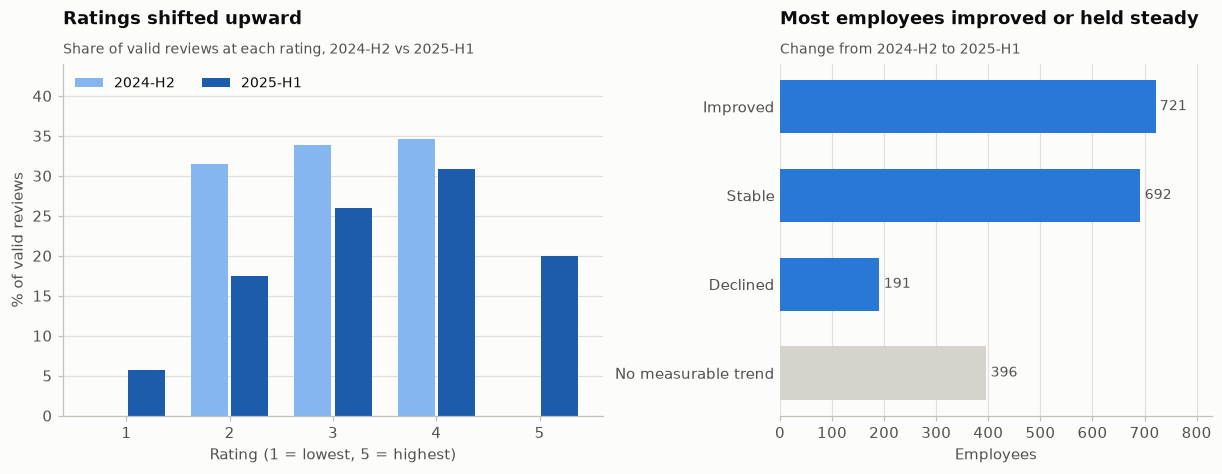

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})

x = np.arange(1, 6)
w = 0.36
for i, period in enumerate([PREV, LATEST]):
    a1.bar(x + (i - 0.5) * (w + 0.03), dist.loc[period] * 100, width=w, color=PERIOD[period], label=period)
a1.set_xticks(x, [f"{r}" for r in x])
a1.set_xlabel("Rating (1 = lowest, 5 = highest)")
a1.set_ylabel("% of valid reviews")
a1.set_ylim(0, 44)
a1.grid(axis="y"); a1.set_axisbelow(True)
a1.legend(loc="upper left", ncols=2)
titled(a1, "Ratings shifted upward", f"Share of valid reviews at each rating, {PREV} vs {LATEST}")

order = ["improved", "stable", "declined", "insufficient_data"]
counts = [int(trend.get(k, 0)) for k in order]
hbars(a2, ["Improved", "Stable", "Declined", "No measurable trend"], counts,
      colors=[ACCENT, ACCENT, ACCENT, DEEMPH])
a2.set_xlabel("Employees")
titled(a2, "Most employees improved or held steady", f"Change from {PREV} to {LATEST}")
plt.show()

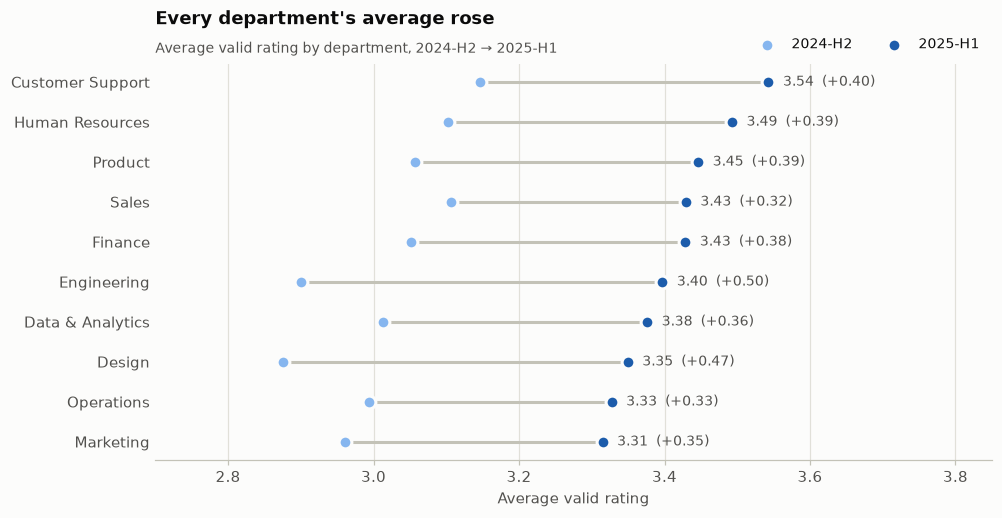

In [7]:
dept = (valid_history.pivot_table(index="department", columns="review_period", values="rating", aggfunc="mean")
        .sort_values(LATEST))
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(dept))
ax.hlines(y, dept[PREV], dept[LATEST], color=AXIS, lw=2, zorder=1)
for period in (PREV, LATEST):
    ax.scatter(dept[period], y, s=70, color=PERIOD[period], edgecolor=SURFACE, linewidth=2, zorder=2, label=period)
for yi, (lo, hi) in enumerate(zip(dept[PREV], dept[LATEST])):
    ax.text(hi + 0.02, yi, f"{hi:.2f}  (+{hi - lo:.2f})", va="center", fontsize=9, color=INK2)
ax.set_yticks(y, dept.index)
ax.set_xlim(2.7, 3.85)
ax.set_xlabel("Average valid rating")
ax.grid(axis="x"); ax.set_axisbelow(True)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncols=2)
titled(ax, "Every department's average rose", f"Average valid rating by department, {PREV} → {LATEST}")
plt.show()

**Look up any employee.** `show_employee(id)` prints the full review history plus the summary, so the "for each employee" part of the question is one call away. Example:

In [8]:
def show_employee(employee_id: int) -> None:
    s = summary[summary.employee_id == employee_id]
    if s.empty:
        print(f"No employee {employee_id}")
        return
    s = s.iloc[0]
    say(f"**{s.first_name} {s.last_name}** (#{employee_id}), {s.job_level}, {s.team_name}, {s.department}")
    h = history[history.employee_id == employee_id][
        ["review_period", "rating", "manager_comment", "submitted_date", "flag_period_before_hire"]]
    table(h.rename(columns={"flag_period_before_hire": "dated before hire"}))
    change = "-" if pd.isna(s.rating_change) else f"{s.rating_change:+.0f}"
    say(f"Trend: **{s.trend}** (change {change}), latest valid rating: "
        f"**{'-' if pd.isna(s.latest_rating) else int(s.latest_rating)}**")


show_employee(1)

**Heather Davis** (#1), Director, Team LightYellow-1, Sales

review_period,rating,manager_comment,submitted_date,dated before hire
2024-H2,3,Delivered on commitments with no major concerns.,2025-08-31,False
2025-H1,4,Delivered on commitments with no major concerns.,2026-02-27,False


Trend: **improved** (change +1), latest valid rating: **4**

In [9]:
say("**Ratings by department (table view).**")
table(dept.assign(change=lambda d: d[LATEST] - d[PREV]).sort_values(LATEST, ascending=False).round(2).reset_index())

**Ratings by department (table view).**

review_period,department,2024-H2,2025-H1,change
,Customer Support,3.15,3.54,0.40
,Human Resources,3.10,3.49,0.39
,Product,3.06,3.45,0.39
,Sales,3.11,3.43,0.32
,Finance,3.05,3.43,0.38
,Engineering,2.90,3.40,0.50
,Data & Analytics,3.01,3.38,0.36
,Design,2.88,3.35,0.47
,Operations,2.99,3.33,0.33
,Marketing,2.96,3.31,0.35


**Caveats**
- **Only two review periods.** A "trend" is a single change, not a pattern over time.
- **Ratings rose in every department** (+0.32 to +0.50). In 2024-H2 nobody received a 1 or a 5; in 2025-H1, 20% received a 5. This looks like a change in how ratings were given, not only real improvement, so compare employees within a period rather than across periods where possible.
- **396 employees have no measurable trend** because one or both reviews are dated before their hire. Their reviews remain in the history, flagged.
- **Manager comments** are 9 stock phrases, so they add no information beyond the rating.

## Q2. Which employees have critical skill gaps in key competencies?

**How it is answered:** `employee_skill_gaps` has one row per competency assessment (4,000; two per employee).
- **Shortfall** = required level − actual proficiency (0 when the requirement is met).
- **Key competency** = one the role requires at the highest level used, **level 4**.
- **Critical gap** = a shortfall of **2 or more levels** on any competency, or **any shortfall on a key competency**.

In [10]:
crit = gaps[gaps["is_critical"]]
two_level = int((crit["shortfall"] >= 2).sum())
key_one = int(((crit["shortfall"] == 1) & crit["is_key"]).sum())
per_emp = crit.groupby("employee_id").size()
dept_rate = gaps.groupby("department")["is_critical"].mean().sort_values(ascending=False)
say(f"""
**Answer.** **{crit_emp:,} employees ({crit_emp / N_EMP:.0%})** have at least one critical gap, across **{len(crit):,}** assessments:
{two_level} are 2+ levels short, and {key_one} are 1 level short on a key competency.
{int((per_emp == 1).sum())} employees have one critical gap and {int((per_emp >= 2).sum())} have two.
The highest critical-gap rates are in **{', '.join(competencies.sort_values('critical_gap_rate', ascending=False).competency_name.head(3))}**.
By department, **{dept_rate.index[0]}** ({dept_rate.iloc[0]:.0%}) and **{dept_rate.index[1]}** ({dept_rate.iloc[1]:.0%}) have the most; **{dept_rate.index[-1]}** ({dept_rate.iloc[-1]:.0%}) the fewest.
Gaps are spread evenly across Technical, Leadership and Domain skills: there is no category-wide weakness.
""")


**Answer.** **441 employees (22%)** have at least one critical gap, across **465** assessments:
325 are 2+ levels short, and 140 are 1 level short on a key competency.
417 employees have one critical gap and 24 have two.
The highest critical-gap rates are in **Stakeholder Management, Security Fundamentals, Communication**.
By department, **Human Resources** (15%) and **Sales** (14%) have the most; **Customer Support** (9%) the fewest.
Gaps are spread evenly across Technical, Leadership and Domain skills: there is no category-wide weakness.


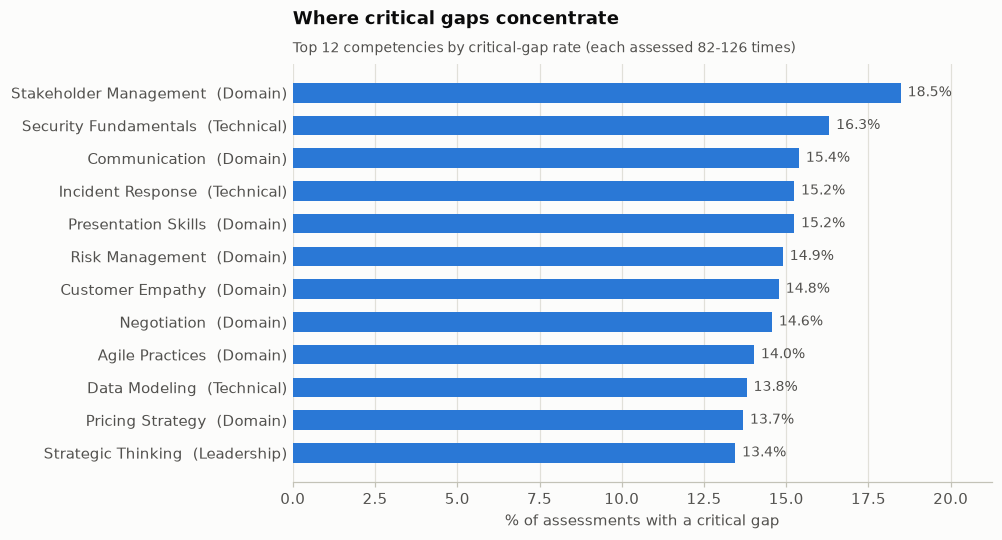

In [11]:
top = competencies.sort_values("critical_gap_rate", ascending=False).head(12)
fig, ax = plt.subplots(figsize=(9, 4.8))
hbars(ax, [f"{n}  ({c})" for n, c in zip(top.competency_name, top.category)], top.critical_gap_rate * 100,
      fmt="{:.1f}%")
ax.set_xlabel("% of assessments with a critical gap")
titled(ax, "Where critical gaps concentrate", "Top 12 competencies by critical-gap rate (each assessed 82-126 times)")
plt.show()

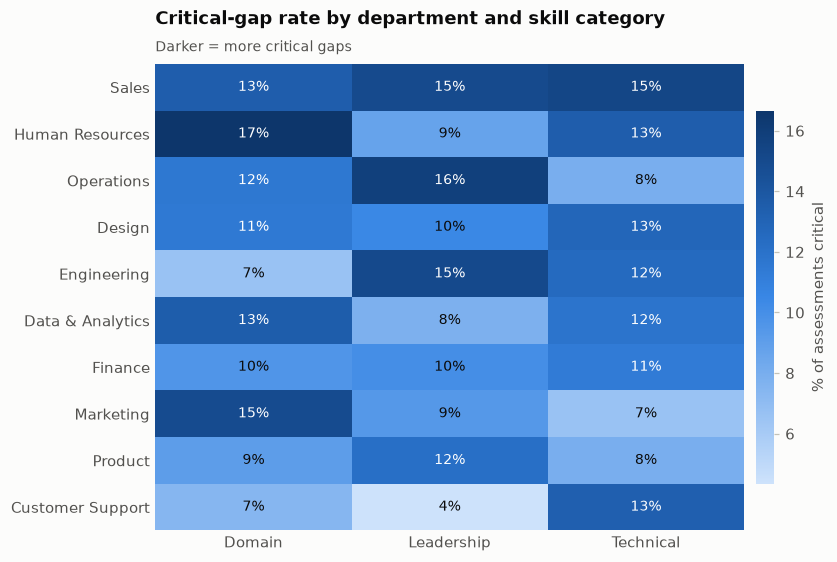

In [12]:
grid = (gaps.pivot_table(index="department", columns="category", values="is_critical", aggfunc="mean") * 100)
grid = grid.loc[grid.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7.5, 5))
heatmap(ax, grid, "{:.0f}%", "% of assessments critical")
titled(ax, "Critical-gap rate by department and skill category", "Darker = more critical gaps")
plt.show()

In [13]:
say("**Employees with critical gaps** (most severe first: 2-level shortfalls on key competencies, then the rest).")
view = (crit.sort_values(["shortfall", "is_key", "department", "employee_id"], ascending=[False, False, True, True])
        [["employee_id", "first_name", "last_name", "department", "job_level", "competency_name", "category",
          "proficiency_level", "required_level", "shortfall", "is_key"]]
        .rename(columns={"competency_name": "competency", "proficiency_level": "has", "required_level": "needs",
                         "is_key": "key"}))
table(view, max_rows=15)

**Employees with critical gaps** (most severe first: 2-level shortfalls on key competencies, then the rest).

employee_id,first_name,last_name,department,job_level,competency,category,has,needs,shortfall,key
101,Amanda,Jackson,Customer Support,Senior Manager,Technical Writing,Domain,2,4,2,True
232,Joseph,Ferrell,Customer Support,IC3,Time Management,Domain,2,4,2,True
588,Kelly,Henderson,Customer Support,Director,Vendor Management,Domain,2,4,2,True
589,Michael,Abbott,Customer Support,IC1,Negotiation,Domain,2,4,2,True
799,Kelly,Hickman,Customer Support,Director,Stakeholder Management,Domain,2,4,2,True
879,James,Bean,Customer Support,Senior Manager,Negotiation,Domain,2,4,2,True
1246,Cynthia,Schwartz,Customer Support,IC3,Incident Response,Technical,2,4,2,True
1254,Craig,Wright,Customer Support,Director,Localization,Domain,2,4,2,True
1511,Sharon,Collins,Customer Support,IC3,Coaching & Mentoring,Leadership,2,4,2,True
1554,Edward,Wade,Customer Support,IC3,Incident Response,Technical,2,4,2,True


*Showing 15 of 465 rows.*

**Caveats**
- Each employee was assessed on **only 2 of 40 competencies**, so "no critical gap" means none among the *assessed* skills, not a full skills audit.
- "Key" (required at level 4) and "critical" (2+ levels short, or short on a key competency) are **our definitions**, chosen because the data has no "key competency" field. They are constants in the pipeline and easy to change.
- 234 assessments are dated before the employee's hire. They are kept (they may be pre-hire assessments) and flagged in Gold.

## Q3. Who are the high-potential employees ready for promotion?

**How it is answered:** `promotion_candidates` holds every employee whose talent review says **potential = High** and **readiness = Ready Now**.

Potential on its own turned out not to reflect performance (see the second chart). So candidates are **tiered by their latest valid rating**:

| Tier | Rule | Recommendation |
|---|---|---|
| **A** | latest rating 4-5 | promote now |
| **B** | latest rating 3 | promote after calibration with the manager |
| **C** | latest rating 1-2, or no valid rating | hold: potential is not backed by performance |

**Retention priority** marks tier A candidates whose recorded attrition risk is High.

In [14]:
by_potential = watch.groupby("potential_rating")["latest_rating"].mean().reindex(["High", "Medium", "Low"])
say(f"""
**Answer.** **{len(candidates)} employees** are high potential and ready now. **{tiers.get('A', 0)} are tier A (promote now)**,
{tiers.get('B', 0)} tier B (calibrate first) and {tiers.get('C', 0)} tier C (hold).
**{int(candidates['retention_priority'].sum())} tier A candidates are also a high attrition risk**: promote them, or risk losing them.
Candidates come from every level: {int(candidates.job_level.str.contains('IC').sum())} individual contributors (IC1-IC3, Senior IC), {int(candidates.job_level.str.contains('Manager').sum())} managers (Manager, Senior Manager) and {int((candidates.job_level == 'Director').sum())} directors, across every department.

Why tiers are needed: the average latest rating is almost identical for High ({by_potential['High']:.2f}), Medium ({by_potential['Medium']:.2f}) and Low ({by_potential['Low']:.2f}) potential employees,
so the potential label alone does not identify strong performers.
""")


**Answer.** **357 employees** are high potential and ready now. **148 are tier A (promote now)**,
90 tier B (calibrate first) and 119 tier C (hold).
**18 tier A candidates are also a high attrition risk**: promote them, or risk losing them.
Candidates come from every level: 191 individual contributors (IC1-IC3, Senior IC), 106 managers (Manager, Senior Manager) and 60 directors, across every department.

Why tiers are needed: the average latest rating is almost identical for High (3.40), Medium (3.45) and Low (3.39) potential employees,
so the potential label alone does not identify strong performers.


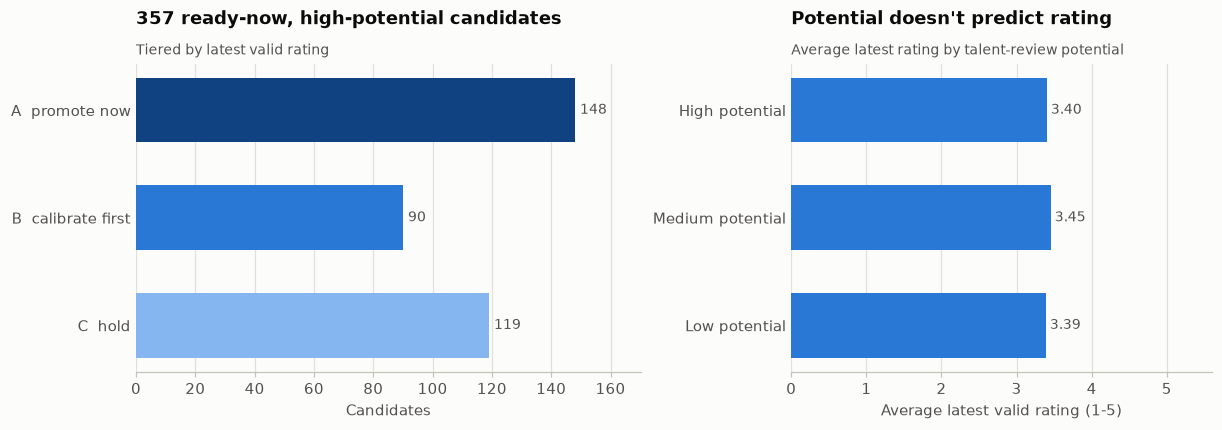

In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
labels = ["A  promote now", "B  calibrate first", "C  hold"]
hbars(a1, labels, [int(tiers.get(t, 0)) for t in "ABC"], colors=[TIER[t] for t in "ABC"])
a1.set_xlabel("Candidates")
titled(a1, f"{len(candidates)} ready-now, high-potential candidates", "Tiered by latest valid rating")

hbars(a2, ["High potential", "Medium potential", "Low potential"], by_potential.to_list(), fmt="{:.2f}", xmax=5.6)
a2.set_xlabel("Average latest valid rating (1-5)")
titled(a2, "Potential doesn't predict rating", "Average latest rating by talent-review potential")
plt.show()

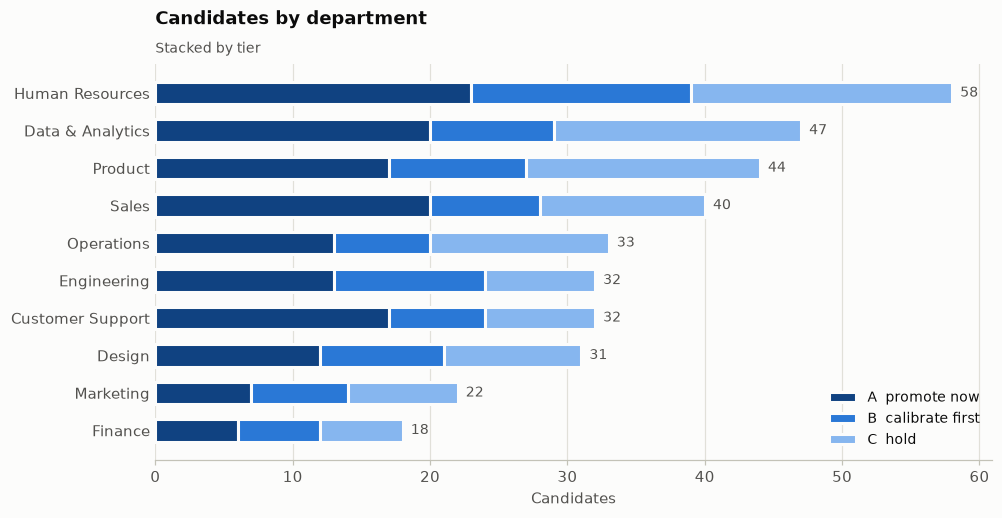

In [16]:
dept_tier = candidates.pivot_table(index="department", columns="tier", values="employee_id", aggfunc="count",
                                   fill_value=0).reindex(columns=list("ABC"), fill_value=0)
dept_tier = dept_tier.loc[dept_tier.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(9, 4.6))
left = np.zeros(len(dept_tier))
for t, lab in zip("ABC", labels):
    ax.barh(dept_tier.index, dept_tier[t], left=left, height=0.6, color=TIER[t], edgecolor=SURFACE, linewidth=2,
            label=lab)
    left += dept_tier[t].to_numpy()
for yi, total in enumerate(left):
    ax.text(total + 0.6, yi, f"{int(total)}", va="center", fontsize=9, color=INK2)
ax.set_xlabel("Candidates")
ax.grid(axis="x"); ax.set_axisbelow(True)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right")
titled(ax, "Candidates by department", "Stacked by tier")
plt.show()

In [17]:
cols = ["rank", "employee_id", "first_name", "last_name", "department", "job_level", "latest_rating", "trend",
        "certifications", "attrition_risk", "retention_priority"]
say("**Tier A: promote now** (ranked by rating, then certifications and courses completed).")
table(candidates[candidates.tier == "A"][cols].astype({"latest_rating": "Int64"}), max_rows=15)
say("**Retention priority:** tier A candidates with a high recorded attrition risk.")
table(candidates[candidates.retention_priority][cols[:-1]].astype({"latest_rating": "Int64"}))

**Tier A: promote now** (ranked by rating, then certifications and courses completed).

rank,employee_id,first_name,last_name,department,job_level,latest_rating,trend,certifications,attrition_risk,retention_priority
1,932,Donald,Nichols,Product,IC2,5,improved,5,Low,False
2,1527,Sarah,Rivera,Sales,Senior Manager,5,improved,3,Low,False
3,1833,Linda,Crawford,Sales,IC2,5,improved,3,Medium,False
4,701,Yolanda,Foley,Marketing,IC2,5,improved,3,Low,False
5,1484,Melissa,Anderson,Design,IC2,5,improved,3,Low,False
6,145,Lisa,Johnson,Product,Manager,5,improved,2,Medium,False
7,749,Nicholas,Bass,Data & Analytics,IC3,5,improved,2,High,True
8,988,Brian,Moore,Sales,IC1,5,improved,2,High,True
9,1346,Thomas,Walker,Human Resources,IC2,5,improved,2,Low,False
10,1435,Barbara,Lozano,Product,IC1,5,improved,2,Low,False


*Showing 15 of 148 rows.*

**Retention priority:** tier A candidates with a high recorded attrition risk.

rank,employee_id,first_name,last_name,department,job_level,latest_rating,trend,certifications,attrition_risk
7,749,Nicholas,Bass,Data & Analytics,IC3,5,improved,2,High
8,988,Brian,Moore,Sales,IC1,5,improved,2,High
12,84,Daniel,Osborne,Customer Support,Manager,5,improved,2,High
15,272,Paul,Smith,Engineering,IC3,5,improved,1,High
18,94,Richard,Tapia,Customer Support,Senior IC,5,improved,1,High
50,1750,Kevin,Bryant,Finance,IC2,5,improved,0,High
63,1867,Martha,Thompson,Data & Analytics,Director,4,improved,2,High
64,157,Dennis,Scott,Engineering,IC2,4,stable,2,High
68,1118,Jonathan,Holmes,Operations,IC3,4,improved,2,High
78,1862,Zachary,Collins,Data & Analytics,IC2,4,insufficient_data,2,High


**Caveats**
- Potential and readiness come from a **single talent-review cycle** (2025-H1).
- **Tier C includes employees with no valid rating** (their reviews are dated before their hire). They may deserve a fresh review rather than a "hold".
- Tiers are a recommendation for discussion, not a decision. Business needs and open roles are not in the data.

## Q4. What training and development has each employee completed?

**How it is answered:** `employee_learning` has one row per employee: distinct courses completed, certifications earned, quizzes passed, average quiz score and first and last activity dates. `employee_course_completions` lists each course an employee completed or was certified in, with the first date.

Completions are **counted directly**. In this data most completions have no matching enrolment, and most certifications have no matching completion, so a "completion rate" (completed ÷ enrolled) would be misleading.

In [18]:
cc = learning["courses_completed"]
top_courses = (completions[completions.completed].groupby("course_name").size().sort_values(ascending=False))
say(f"""
**Answer.** **{completed_any:,} employees ({completed_any / N_EMP:.0%})** completed at least one course, and
**{certified_any:,} ({certified_any / N_EMP:.0%})** earned at least one certification.
The typical employee completed **{cc.median():.0f}** course(s) (average {cc.mean():.1f}, maximum {cc.max()}); {int((cc == 0).sum())} completed none.
In total there are **{int(completions.completed.sum()):,} course completions** and **{int(completions.certified.sum()):,} certifications** across {completions.course_name.nunique()} courses.
The most completed courses are **{', '.join(top_courses.index[:3])}**.
The average quiz score is **{learning.avg_quiz_score.mean():.0f}** out of 100.
""")


**Answer.** **1,661 employees (83%)** completed at least one course, and
**1,154 (58%)** earned at least one certification.
The typical employee completed **2** course(s) (average 1.7, maximum 7); 339 completed none.
In total there are **3,429 course completions** and **1,757 certifications** across 42 courses.
The most completed courses are **Agile Practices Certification, Cloud Architecture Fundamentals, Customer Empathy Workshop**.
The average quiz score is **67** out of 100.


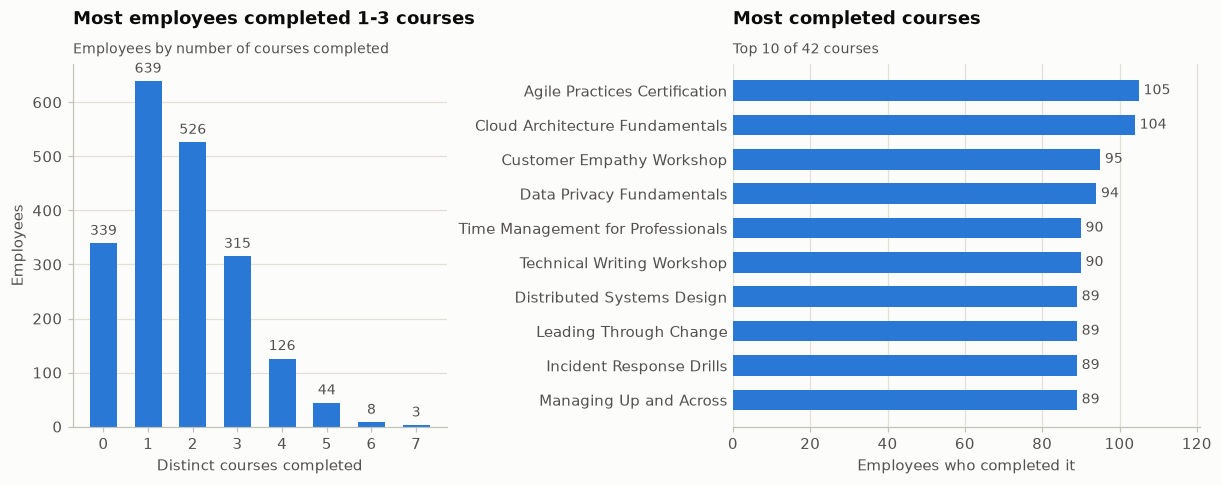

In [19]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw={"width_ratios": [1, 1.25]})
hist = cc.value_counts().sort_index()
a1.bar(hist.index, hist.values, width=0.6, color=ACCENT)
for xi, v in zip(hist.index, hist.values):
    a1.text(xi, v + hist.max() * 0.015, f"{v:,}", ha="center", va="bottom", fontsize=9, color=INK2)
a1.set_xticks(hist.index)
a1.set_xlabel("Distinct courses completed")
a1.set_ylabel("Employees")
a1.grid(axis="y"); a1.set_axisbelow(True)
titled(a1, "Most employees completed 1-3 courses", "Employees by number of courses completed")

top10 = top_courses.head(10)
hbars(a2, top10.index, top10.values)
a2.set_xlabel("Employees who completed it")
titled(a2, "Most completed courses", "Top 10 of 42 courses")
plt.show()

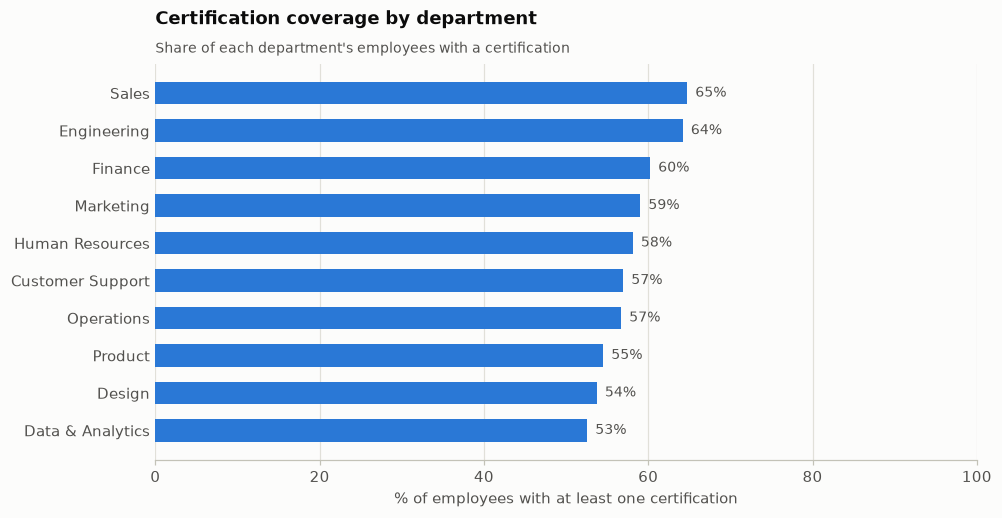

In [20]:
dept_learn = (learning.groupby("department")
              .agg(employees=("employee_id", "size"),
                   completed_a_course=("courses_completed", lambda s: (s > 0).mean()),
                   certified=("certifications", lambda s: (s > 0).mean()),
                   avg_courses=("courses_completed", "mean"))
              .sort_values("certified"))
fig, ax = plt.subplots(figsize=(9, 4.6))
hbars(ax, dept_learn.index, dept_learn["certified"] * 100, fmt="{:.0f}%", xmax=100)
ax.invert_yaxis()
ax.set_xlabel("% of employees with at least one certification")
titled(ax, "Certification coverage by department", "Share of each department's employees with a certification")
plt.show()

In [21]:
say("**By department (table view).**")
table(dept_learn.sort_values("certified", ascending=False).reset_index()
      .assign(completed_a_course=lambda d: d.completed_a_course.map(pct), certified=lambda d: d.certified.map(pct),
              avg_courses=lambda d: d.avg_courses.round(2)))


def show_training(employee_id: int) -> None:
    """Q4 for one employee: totals plus every course completed or certified."""
    row = learning[learning.employee_id == employee_id]
    table(row[["employee_id", "first_name", "last_name", "courses_completed", "certifications", "quizzes_passed",
               "avg_quiz_score", "first_activity_date", "last_activity_date"]])
    table(completions[completions.employee_id == employee_id].drop(columns="employee_id"))


say("**Per employee:** `show_training(id)`. Example:")
show_training(1)

**By department (table view).**

department,employees,completed_a_course,certified,avg_courses
Sales,241,86%,65%,1.85
Engineering,148,86%,64%,1.78
Finance,93,83%,60%,1.85
Marketing,122,81%,59%,1.65
Human Resources,327,79%,58%,1.58
Customer Support,209,83%,57%,1.53
Operations,187,79%,57%,1.59
Product,211,84%,55%,1.85
Design,188,83%,54%,1.73
Data & Analytics,274,86%,53%,1.81


**Per employee:** `show_training(id)`. Example:

employee_id,first_name,last_name,courses_completed,certifications,quizzes_passed,avg_quiz_score,first_activity_date,last_activity_date
1,Heather,Davis,2,1,3,65.5,2023-09-27,2026-06-23


course_name,completed,completed_date,certified,certified_date,date_repaired
Cloud Architecture Fundamentals,False,None,True,2023-11-22,False
Distributed Systems Design,True,2024-09-17,False,None,False
SQL Performance Tuning,True,2026-02-24,False,None,False


**Caveats**
- **There is no data on development plans or goals.** The brief mentions them, but the source has none, so this answers *training completed* only.
- **The events don't form a complete course journey.** Most completions have no enrolment, and most certifications have no completion, probably because enrolments happened before the data starts (September 2023). Counts are reliable; completion rates are not.
- **76 events could not be credited to anyone** (no employee ID). They were quarantined in Silver.
- 53 events had an unreadable date that was repaired to the day of their source folder. Day-level counts are unaffected (flagged in `date_repaired`).

## Q5. Which employees are at risk of attrition based on performance trends?

**How it is answered:** `attrition_watchlist` has one row per employee and combines two independent sources:
- **Performance signal** (from ratings): the rating **declined** from the previous to the latest period, *or* the latest rating is **2 or lower**.
- **Recorded attrition risk** (from the talent review): Low, Medium or High.

| Risk tier | Rule |
|---|---|
| **Critical** | performance signal **and** recorded risk High |
| **High** | signal and Medium risk, *or* High risk without a signal |
| **Watch** | signal and Low risk |
| **Low** | everything else |

In [22]:
w = watch.dropna(subset=["rating_change"])
r = np.corrcoef(w["rating_change"], w["recorded_attrition_risk"].map({"Low": 0, "Medium": 1, "High": 2}))[0, 1]
by_risk = w.groupby("recorded_attrition_risk")["rating_change"].mean().reindex(["Low", "Medium", "High"])
crit_hp = watch[(watch.risk_tier == "Critical") & watch.high_potential]
say(f"""
**Answer.** **{risk.get('Critical', 0)} employees are Critical**, {risk.get('High', 0)} High, {risk.get('Watch', 0)} Watch and {risk.get('Low', 0):,} Low.
**{len(crit_hp)} of the Critical employees are high potential**: these are the losses that would hurt most.

The performance signal and the recorded risk agree. Employees recorded as High risk saw their rating **fall** by {abs(by_risk['High']):.2f} on average,
while Low-risk employees' ratings **rose** by {by_risk['Low']:.2f} (correlation r = {r:.2f} across {len(w):,} employees with a trend).
""")


**Answer.** **143 employees are Critical**, 294 High, 171 Watch and 1,392 Low.
**42 of the Critical employees are high potential**: these are the losses that would hurt most.

The performance signal and the recorded risk agree. Employees recorded as High risk saw their rating **fall** by 0.30 on average,
while Low-risk employees' ratings **rose** by 0.57 (correlation r = -0.30 across 1,604 employees with a trend).


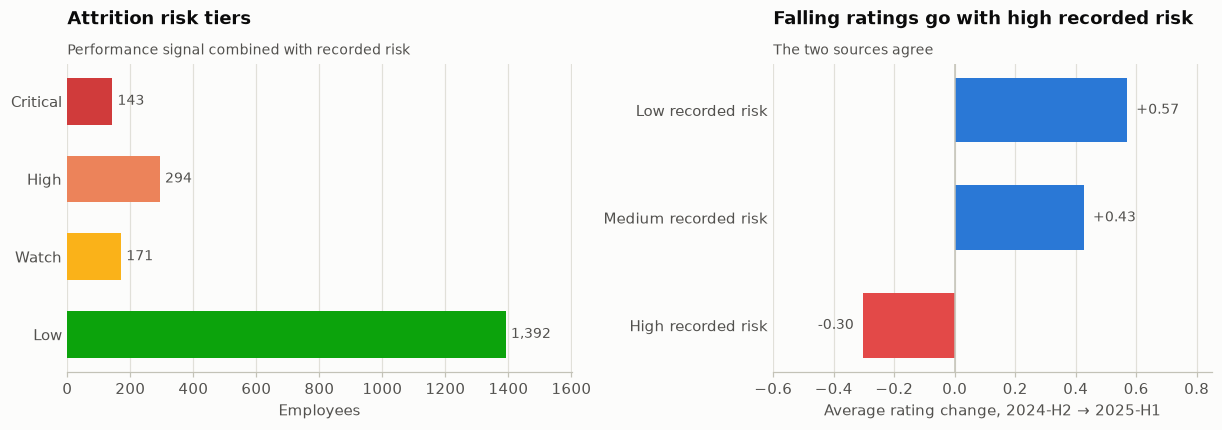

In [23]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.15, 1]})
order = ["Critical", "High", "Watch", "Low"]
hbars(a1, [f"{t}" for t in order], [int(risk.get(t, 0)) for t in order], colors=[STATUS[t] for t in order])
a1.set_xlabel("Employees")
titled(a1, "Attrition risk tiers", "Performance signal combined with recorded risk")

vals = by_risk.to_numpy()
y = np.arange(3)
a2.barh(y, vals, height=0.6, color=[ACCENT if v >= 0 else RED for v in vals])
a2.axvline(0, color=AXIS, lw=1)
for yi, v in zip(y, vals):
    a2.text(v + (0.03 if v >= 0 else -0.03), yi, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right",
            fontsize=9, color=INK2)
a2.set_yticks(y, [f"{k} recorded risk" for k in by_risk.index])
a2.invert_yaxis()
a2.set_xlim(-0.6, 0.85)
a2.set_xlabel(f"Average rating change, {PREV} → {LATEST}")
a2.grid(axis="x"); a2.set_axisbelow(True)
a2.spines["left"].set_visible(False); a2.tick_params(axis="y", length=0)
titled(a2, "Falling ratings go with high recorded risk", "The two sources agree")
plt.show()

In [24]:
cols = ["employee_id", "first_name", "last_name", "department", "job_level", "previous_rating",
        "latest_period_rating", "rating_change", "signal_reason", "recorded_attrition_risk"]
fmt = {"previous_rating": "Int64", "latest_period_rating": "Int64", "rating_change": "Int64"}
say("**Critical and high potential: act first.**")
table(crit_hp.sort_values(["rating_change", "employee_id"])[cols].astype(fmt))
say("**All Critical employees** (largest rating drop first).")
table(watch[watch.risk_tier == "Critical"].sort_values(["rating_change", "employee_id"])[cols].astype(fmt), max_rows=15)
say("**Risk tier by department.**")
table(watch.pivot_table(index="department", columns="risk_tier", values="employee_id", aggfunc="count", fill_value=0)
      .reindex(columns=order).sort_values("Critical", ascending=False).reset_index())

**Critical and high potential: act first.**

employee_id,first_name,last_name,department,job_level,previous_rating,latest_period_rating,rating_change,signal_reason,recorded_attrition_risk
245,Karen,Rosales,Customer Support,Manager,4,2,-2,rating declined; latest rating <= 2,High
295,Paula,Davies,Product,Manager,3,1,-2,rating declined; latest rating <= 2,High
361,Desiree,Robertson,Data & Analytics,Director,3,1,-2,rating declined; latest rating <= 2,High
521,Charles,Smith,Operations,IC1,3,1,-2,rating declined; latest rating <= 2,High
732,Seth,Gay,Design,Senior Manager,3,1,-2,rating declined; latest rating <= 2,High
842,Laurie,Schneider,Marketing,IC1,3,1,-2,rating declined; latest rating <= 2,High
1127,Alexandra,Lee,Operations,IC3,3,1,-2,rating declined; latest rating <= 2,High
1243,Ashley,Hubbard,Marketing,IC3,3,1,-2,rating declined; latest rating <= 2,High
1306,Randall,King,Design,Director,3,1,-2,rating declined; latest rating <= 2,High
1448,Kelly,Turner,Marketing,Senior Manager,4,2,-2,rating declined; latest rating <= 2,High


**All Critical employees** (largest rating drop first).

employee_id,first_name,last_name,department,job_level,previous_rating,latest_period_rating,rating_change,signal_reason,recorded_attrition_risk
194,Carly,Bennett,Data & Analytics,Director,3,1,-2,rating declined; latest rating <= 2,High
237,Nicholas,Gonzales,Customer Support,IC1,4,2,-2,rating declined; latest rating <= 2,High
245,Karen,Rosales,Customer Support,Manager,4,2,-2,rating declined; latest rating <= 2,High
257,Raymond,Waters,Marketing,Director,3,1,-2,rating declined; latest rating <= 2,High
295,Paula,Davies,Product,Manager,3,1,-2,rating declined; latest rating <= 2,High
357,Juan,Thomas,Data & Analytics,Director,4,2,-2,rating declined; latest rating <= 2,High
361,Desiree,Robertson,Data & Analytics,Director,3,1,-2,rating declined; latest rating <= 2,High
371,Anne,Long,Operations,IC1,4,2,-2,rating declined; latest rating <= 2,High
521,Charles,Smith,Operations,IC1,3,1,-2,rating declined; latest rating <= 2,High
657,Kenneth,Kane,Data & Analytics,IC3,4,2,-2,rating declined; latest rating <= 2,High


*Showing 15 of 143 rows.*

**Risk tier by department.**

risk_tier,department,Critical,High,Watch,Low
,Sales,22,33,22,164
,Data & Analytics,21,35,28,190
,Human Resources,20,51,25,231
,Customer Support,15,31,11,152
,Marketing,13,12,11,86
,Operations,13,25,22,127
,Design,12,34,16,126
,Product,11,36,15,149
,Engineering,10,26,13,99
,Finance,6,11,8,68


**Caveats**
- **The trend is one change between two periods.** It shows direction, not a sustained decline.
- **There is no data on who actually left**, so the tiers cannot be checked against real attrition. They identify who to talk to, not who will leave.
- **396 employees have no measurable trend** (reviews dated before hire). They are tiered on their recorded risk alone.
- The company-wide rise in ratings (see Q1) means a decline stands out more; a stable rating may already be relatively weak.

## Q6. How does employee performance correlate with team and project outcomes?

**How it is answered:** only **people on teams with projects** are included: 27 teams, 33 projects.
- `team_performance` has one row per team: the average valid rating of its people, the share of **low performers** (average rating ≤ 2), and its project results (**on-time rate**, average outcome score).
- `project_performance` has one row per project with its type, status, score and the team's ratings.

The tests use **one row per team**, so teams with two projects are not counted twice. Significance comes from permutation tests: the outcomes are shuffled 20,000 times to see how often a link this strong appears by chance.

In [25]:
def perm_test(x, y, rank=False, n=20_000, seed=42):
    """Correlation and two-sided permutation p-value (Spearman when rank=True)."""
    x, y = pd.Series(x, dtype=float), pd.Series(y, dtype=float)
    if rank:
        x, y = x.rank(), y.rank()
    x, y = x.to_numpy(), y.to_numpy()
    r = np.corrcoef(x, y)[0, 1]
    rng = np.random.default_rng(seed)
    null = np.array([np.corrcoef(x, rng.permutation(y))[0, 1] for _ in range(n)])
    return r, (np.abs(null) >= abs(r)).mean()


tests = []
for label, x, y, rank in [
    ("Team avg rating vs on-time rate", teams.avg_rating, teams.on_time_rate, True),
    ("Team avg rating vs avg outcome score", teams.avg_rating, teams.avg_outcome_score, False),
    ("Share of low performers vs delay rate", teams.low_performer_share, 1 - teams.on_time_rate, False),
]:
    r_, p_ = perm_test(x, y, rank=rank)
    tests.append((label, "Spearman (rank)" if rank else "Pearson", round(r_, 2), round(p_, 3),
                  "yes" if p_ < 0.05 else "no"))
tests = pd.DataFrame(tests, columns=["Relationship", "Measure", "r", "p-value", "Significant (p < 0.05)"])

bands = (teams.groupby("rating_band").agg(teams=("team_id", "size"), avg_rating=("avg_rating", "mean"),
                                          on_time=("on_time_rate", "mean"), avg_score=("avg_outcome_score", "mean"))
         .reindex(["bottom third", "middle third", "top third"]))
types = (projects.groupby("project_type").agg(projects=("project_id", "size"), on_time=("on_time", "mean"),
                                              avg_score=("outcome_score", "mean")).sort_values("on_time"))
teams["outcome_group"] = np.select([teams.on_time_rate == 1, teams.on_time_rate == 0],
                                   ["all on time", "all delayed"], "mixed")
groups = (teams.groupby("outcome_group").agg(teams=("team_id", "size"), low_share=("low_performer_share", "mean"))
          .reindex(["all on time", "mixed", "all delayed"]))
r1, p1 = tests.loc[0, ["r", "p-value"]]
r2, p2 = tests.loc[1, ["r", "p-value"]]
r3, p3 = tests.loc[2, ["r", "p-value"]]
say(f"""
**Answer.** **Higher-rated teams deliver on time more often, but not with better outcome scores.**
- Teams in the **top third** by average rating delivered **{bands.loc['top third', 'on_time']:.0%}** of their projects on time, against **{bands.loc['bottom third', 'on_time']:.0%}** for the **bottom third** (rank correlation {r1:+.2f}, p ≈ {p1:.2f}).
- Ratings show **no meaningful link to outcome scores** (r = {r2:+.2f}, p ≈ {p2:.2f}).
- Teams whose projects were all delayed had **{groups.loc['all delayed', 'low_share']:.0%}** low performers, against **{groups.loc['all on time', 'low_share']:.0%}** in teams that were always on time (r = {r3:+.2f}, p ≈ {p3:.2f}).
- **Project type matters too**: only **{types.loc['Migration', 'on_time']:.0%}** of Migrations were on time, against **{types.loc['Revamp', 'on_time']:.0%}** of Revamps.

This is a **moderate association across 27 teams, not proof of cause** (see caveats).
""")


**Answer.** **Higher-rated teams deliver on time more often, but not with better outcome scores.**
- Teams in the **top third** by average rating delivered **94%** of their projects on time, against **44%** for the **bottom third** (rank correlation +0.45, p ≈ 0.02).
- Ratings show **no meaningful link to outcome scores** (r = +0.13, p ≈ 0.50).
- Teams whose projects were all delayed had **29%** low performers, against **16%** in teams that were always on time (r = +0.46, p ≈ 0.01).
- **Project type matters too**: only **38%** of Migrations were on time, against **75%** of Revamps.

This is a **moderate association across 27 teams, not proof of cause** (see caveats).


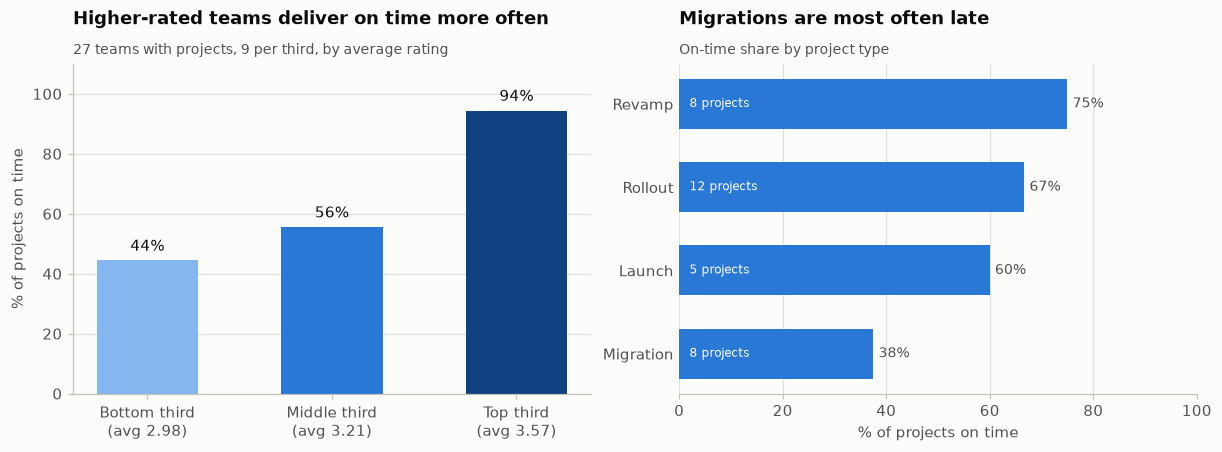

In [26]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1]})
x = np.arange(3)
a1.bar(x, bands["on_time"] * 100, width=0.55, color=[BLUE[250], BLUE[450], BLUE[650]])
for xi, (v, n) in enumerate(zip(bands["on_time"], bands["teams"])):
    a1.text(xi, v * 100 + 2, f"{v:.0%}", ha="center", va="bottom", fontsize=10, color=INK)
a1.set_xticks(x, [f"Bottom third\n(avg {bands.avg_rating.iloc[0]:.2f})", f"Middle third\n(avg {bands.avg_rating.iloc[1]:.2f})",
                  f"Top third\n(avg {bands.avg_rating.iloc[2]:.2f})"])
a1.set_ylim(0, 110); a1.set_ylabel("% of projects on time")
a1.grid(axis="y"); a1.set_axisbelow(True)
titled(a1, "Higher-rated teams deliver on time more often", "27 teams with projects, 9 per third, by average rating")

hbars(a2, types.index[::-1], (types["on_time"] * 100).to_numpy()[::-1], fmt="{:.0f}%", xmax=100)
for yi, n in enumerate(types["projects"].to_numpy()[::-1]):
    a2.text(2, yi, f"{n} projects", va="center", ha="left", fontsize=8, color="white")
a2.set_xlabel("% of projects on time")
titled(a2, "Migrations are most often late", "On-time share by project type")
plt.show()

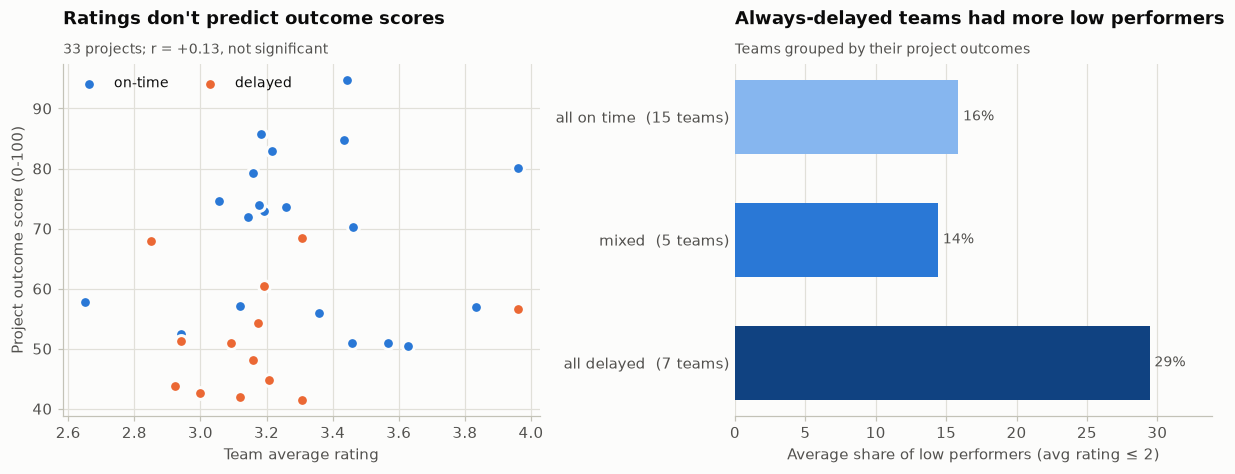

In [27]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
for status, color in (("on-time", ACCENT), ("delayed", ORANGE)):
    s = projects[projects.outcome_status == status]
    a1.scatter(s.team_avg_rating, s.outcome_score, s=60, color=color, edgecolor=SURFACE, linewidth=2, label=status)
a1.set_xlabel("Team average rating"); a1.set_ylabel("Project outcome score (0-100)")
a1.grid(True); a1.set_axisbelow(True)
a1.legend(loc="upper left", ncols=2)
titled(a1, "Ratings don't predict outcome scores", f"33 projects; r = {r2:+.2f}, not significant")

g = groups.dropna()
hbars(a2, [f"{k}  ({int(n)} teams)" for k, n in zip(g.index, g.teams)], g["low_share"] * 100, fmt="{:.0f}%",
      colors=[BLUE[250], BLUE[450], BLUE[650]])
a2.set_xlabel("Average share of low performers (avg rating ≤ 2)")
titled(a2, "Always-delayed teams had more low performers", "Teams grouped by their project outcomes")
plt.show()

In [28]:
say("**Statistical tests (one row per team, 20,000 permutations).**")
table(tests)
say("**All 27 teams (table view)**, highest-rated first.")
show = teams.sort_values("avg_rating", ascending=False)[
    ["team_id", "team_name", "department", "people_rated", "avg_rating", "low_performer_share", "projects",
     "projects_on_time", "on_time_rate", "avg_outcome_score", "rating_band"]]
table(show.assign(avg_rating=lambda d: d.avg_rating.round(2), low_performer_share=lambda d: d.low_performer_share.map(pct),
                  on_time_rate=lambda d: d.on_time_rate.map(pct), avg_outcome_score=lambda d: d.avg_outcome_score.round(1)))

**Statistical tests (one row per team, 20,000 permutations).**

Relationship,Measure,r,p-value,Significant (p < 0.05)
Team avg rating vs on-time rate,Spearman (rank),0.45,0.019,yes
Team avg rating vs avg outcome score,Pearson,0.13,0.503,no
Share of low performers vs delay rate,Pearson,0.46,0.011,yes


**All 27 teams (table view)**, highest-rated first.

team_id,team_name,department,people_rated,avg_rating,low_performer_share,projects,projects_on_time,on_time_rate,avg_outcome_score,rating_band
38,Team Olive-38,Data & Analytics,13,3.96,0%,2,1,50%,68.3,top third
39,Team LemonChiffon-39,Product,12,3.83,8%,1,1,100%,56.9,top third
94,Team Azure-94,Sales,22,3.63,5%,1,1,100%,50.4,top third
64,Team GhostWhite-64,Customer Support,20,3.57,5%,1,1,100%,51.0,top third
8,Team Black-8,Product,26,3.46,12%,1,1,100%,70.3,top third
97,Team LightSalmon-97,Engineering,13,3.46,15%,1,1,100%,50.9,top third
89,Team YellowGreen-89,Human Resources,18,3.44,17%,1,1,100%,94.8,top third
34,Team GreenYellow-34,Operations,12,3.43,17%,1,1,100%,84.7,top third
96,Team Thistle-96,Data & Analytics,15,3.36,13%,1,1,100%,56.0,top third
37,Team Red-37,Design,26,3.31,12%,2,0,0%,55.0,middle third


**Caveats**
- **Small sample:** 27 teams (33 projects); 73 teams have no projects and are not included.
- **No record of who worked on which project.** Projects belong to teams, so the link is at team level. In 5 teams the *same people* delivered one project on time and one late.
- **No project dates.** We can't tell whether a review came before or after a delay, so the direction is unknown: managers may have rated people down *because* a project was late.
- Several tests were run, so a single p ≈ 0.02 is suggestive rather than conclusive.
- Reviews dated before hire are excluded (471 of the 537 people in these teams have a valid review).

## Q7. What is the distribution of skills across the organization?

**How it is answered:** `skill_distribution` counts assessments at each proficiency level (1-5) per competency and department. `competency_summary` has one row per competency: average proficiency, share meeting the required level, critical gaps, and counts at each level.

In [29]:
levels = gaps["proficiency_level"].value_counts(normalize=True).sort_index()
cat = gaps.groupby("category").agg(avg=("proficiency_level", "mean"), meets=("shortfall", lambda s: (s == 0).mean()))
ranked = competencies.sort_values("avg_proficiency")
dept_cat = gaps.pivot_table(index="department", columns="category", values="proficiency_level", aggfunc="mean")
hi_cell, lo_cell = dept_cat.stack().idxmax(), dept_cat.stack().idxmin()
say(f"""
**Answer.** Skills follow a **bell curve centred on level 3**: {levels.get(1, 0):.0%} of assessments at level 1, {levels.get(3, 0):.0%} at level 3, {levels.get(5, 0):.0%} at level 5.
**{meets:.0%} of assessments meet the required level.**
The three categories are almost identical (average proficiency: {', '.join(f'{k} {v:.2f}' for k, v in cat['avg'].items())}), so there is no category-wide weakness.
Strongest competencies: **{', '.join(ranked.competency_name.tail(3)[::-1])}**. Weakest: **{', '.join(ranked.competency_name.head(3))}**
({ranked.competency_name.iloc[0]} averages {ranked.avg_proficiency.iloc[0]:.2f}, and only {ranked.meets_required_share.iloc[0]:.0%} meet the requirement).
By department and category, the highest average is **{hi_cell[0]} / {hi_cell[1]}** ({dept_cat.loc[hi_cell]:.2f}) and the lowest is **{lo_cell[0]} / {lo_cell[1]}** ({dept_cat.loc[lo_cell]:.2f}).
""")


**Answer.** Skills follow a **bell curve centred on level 3**: 13% of assessments at level 1, 28% at level 3, 13% at level 5.
**75% of assessments meet the required level.**
The three categories are almost identical (average proficiency: Domain 3.05, Leadership 3.07, Technical 3.07), so there is no category-wide weakness.
Strongest competencies: **Regulatory Compliance, Localization, Cloud Architecture**. Weakest: **Stakeholder Management, Negotiation, Risk Management**
(Stakeholder Management averages 2.62, and only 65% meet the requirement).
By department and category, the highest average is **Product / Technical** (3.29) and the lowest is **Human Resources / Leadership** (2.85).


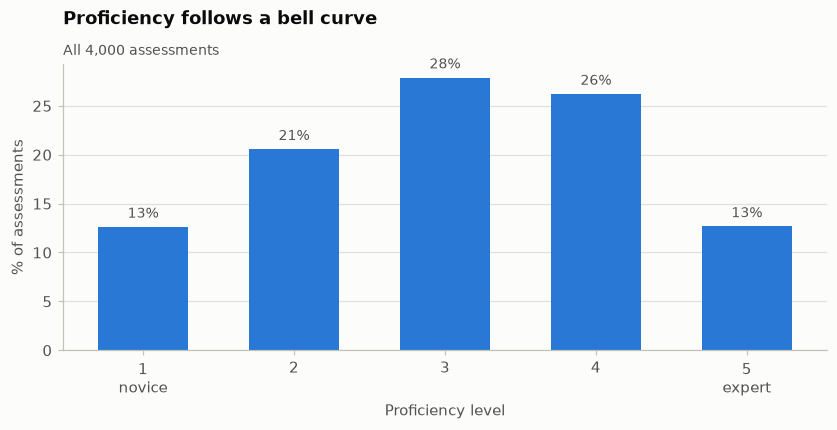

In [30]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(levels.index, levels.values * 100, width=0.6, color=ACCENT)
for xi, v in zip(levels.index, levels.values):
    ax.text(xi, v * 100 + 0.6, f"{v:.0%}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_xticks(levels.index, ["1\nnovice", "2", "3", "4", "5\nexpert"])
ax.set_ylabel("% of assessments"); ax.set_xlabel("Proficiency level")
ax.grid(axis="y"); ax.set_axisbelow(True)
titled(ax, "Proficiency follows a bell curve", f"All {len(gaps):,} assessments")
plt.show()

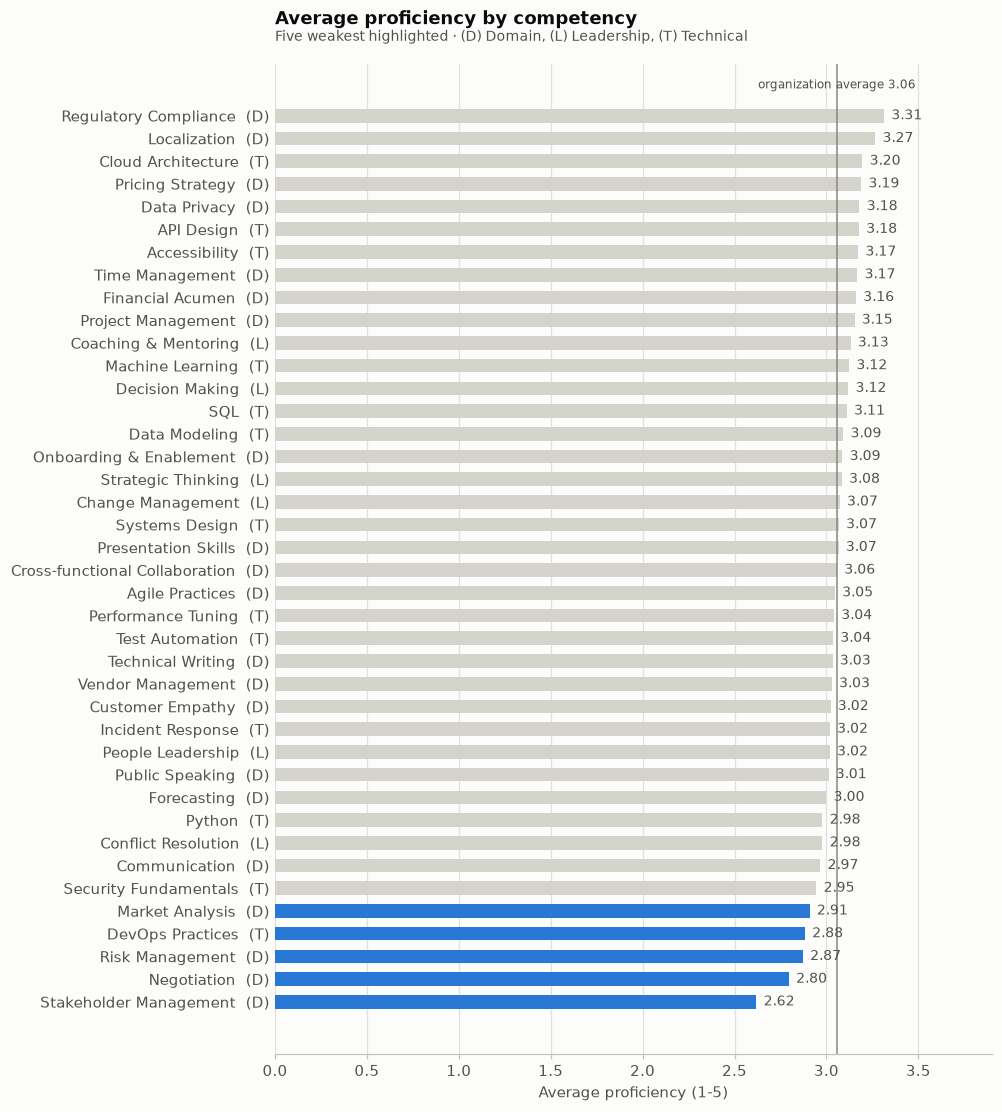

In [31]:
ranked_desc = ranked.iloc[::-1]
weak5 = set(ranked.competency_id.head(5))
colors = [ACCENT if c in weak5 else DEEMPH for c in ranked_desc.competency_id]
fig, ax = plt.subplots(figsize=(9, 10))
hbars(ax, [f"{n}  ({c[0]})" for n, c in zip(ranked_desc.competency_name, ranked_desc.category)],
      ranked_desc.avg_proficiency.to_numpy(), colors=colors, fmt="{:.2f}", xmax=3.9)
org = gaps["proficiency_level"].mean()
ax.axvline(org, color=MUTED, lw=1)
ax.text(org, -1.2, f"organization average {org:.2f}", ha="center", fontsize=8, color=INK2)
ax.set_xlabel("Average proficiency (1-5)")
titled(ax, "Average proficiency by competency", "Five weakest highlighted · (D) Domain, (L) Leadership, (T) Technical")
plt.show()

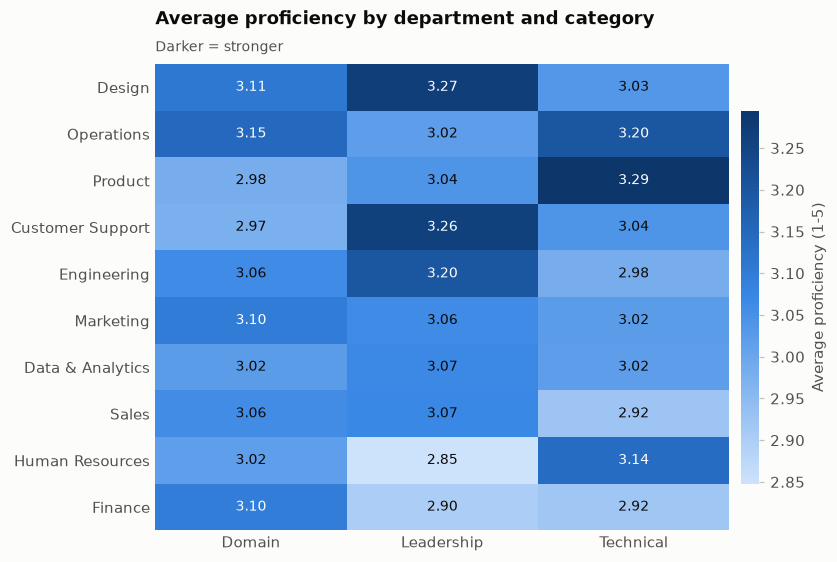

In [32]:
grid = dept_cat.loc[dept_cat.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7.5, 5))
heatmap(ax, grid, "{:.2f}", "Average proficiency (1-5)")
titled(ax, "Average proficiency by department and category", "Darker = stronger")
plt.show()

In [33]:
cols = ["competency_name", "category", "assessed", "avg_proficiency", "meets_required_share", "critical_gap_rate",
        "level_1", "level_2", "level_3", "level_4", "level_5"]
fmt = lambda d: d.assign(avg_proficiency=d.avg_proficiency.round(2), meets_required_share=d.meets_required_share.map(pct),
                         critical_gap_rate=d.critical_gap_rate.map(pct))
say("**All 40 competencies (table view)**, weakest first.")
table(fmt(ranked[cols]))

**All 40 competencies (table view)**, weakest first.

competency_name,category,assessed,avg_proficiency,meets_required_share,critical_gap_rate,level_1,level_2,level_3,level_4,level_5
Stakeholder Management,Domain,92,2.62,65%,18%,20,23,27,16,6
Negotiation,Domain,103,2.80,70%,15%,13,35,27,16,12
Risk Management,Domain,94,2.87,70%,15%,14,26,19,28,7
DevOps Practices,Technical,86,2.88,74%,10%,14,20,23,20,9
Market Analysis,Domain,99,2.91,73%,10%,18,17,30,24,10
Security Fundamentals,Technical,92,2.95,71%,16%,15,22,23,17,15
Communication,Domain,91,2.97,71%,15%,11,22,23,29,6
Conflict Resolution,Leadership,93,2.98,70%,11%,12,22,24,26,9
Python,Technical,93,2.98,73%,10%,12,20,29,22,10
Forecasting,Domain,104,3.00,70%,9%,17,18,31,24,14


**Caveats**
- **This is a sample, not a full inventory.** Each employee was assessed on 2 of 40 competencies, giving 82-126 assessments per competency. Differences of a few hundredths between competencies are within noise.
- Department × category cells hold roughly 40-200 assessments each, so treat small differences there with care too.

## Appendix

### Definitions used in Gold

| Term | Definition |
|---|---|
| Valid review | A review not dated before the employee's hire. Only valid reviews feed ratings, trends and averages. |
| Trend | Latest-period rating minus previous-period rating (both valid): improved, stable, declined; otherwise *insufficient data*. |
| Latest rating | The most recent valid rating, in either period. |
| Key competency | Required at level 4 (the highest level used). |
| Critical gap | Shortfall of 2+ levels, or any shortfall on a key competency. |
| Promotion tier | Among potential *High* + readiness *Ready Now*: A = latest rating 4-5, B = 3, C = otherwise. |
| Retention priority | Tier A with recorded attrition risk High. |
| Performance signal | Rating declined, or latest rating ≤ 2. |
| Risk tier | Critical = signal + High risk; High = signal + Medium, or High without signal; Watch = signal + Low; Low = the rest. |
| Low performer | Person's average valid rating ≤ 2. |
| Project type | Last word of the project name (Launch, Rollout, Migration, Revamp). |

These are constants in `job.py` (Gold section). Every Gold row is validated against them before it is written.

### Data quality notes

- **Learning events:** 13 malformed lines and 76 events without an employee were quarantined. 152 exact duplicates were dropped. 39 events used an old field name (`notes`) and were mapped to `text`. 53 unreadable dates were repaired to the day of their source folder, which the event ID independently confirmed. One source file was empty.
- **Reviews and assessments dated before hire:** 666 reviews and 234 assessments are flagged and kept.
- **Synthetic data signs:** job levels are almost evenly sized (Directors as common as entry-level staff), Human Resources is the largest department, and one team has 53 people against an average of 20.

### How to rerun

```bash
cd data/talent-etl
./scripts/load_source_db.sh            # load the CSVs into PostgreSQL (once)
.venv/bin/python job.py                # Bronze -> Silver -> Gold
.venv/bin/jupyter nbconvert --to notebook --execute --inplace notebooks/talent_insights.ipynb
```

To read Gold from S3 instead of the local folder, set `LAKE_ROOT=s3://<bucket>/<prefix>` before starting Jupyter.